## Setup

In [2]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch


In [3]:
import torch
print("GPU Available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))


GPU Available: False


In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

/opt/anaconda3/envs/CLIP_env_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/lionellopenoni/.cache/kagglehub/datasets/sumn2u/garbage-classification-v2/versions/12


In [5]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


## Image Exploration

In [6]:
from utils import count_observations
# Split dataset into train and test
data_split = dataset.train_test_split(test_size=0.2, shuffle=True, seed=42, stratify_by_column="label")
train = data_split["train"]
test = data_split["test"]
print("Train Split:\n", count_observations(train))
print("\nTest Split:\n", count_observations(test))

Train Split:
         label  count
0     battery    605
1  biological    559
2   cardboard   1129
3     clothes   1513
4       glass   1389
5       metal    744
6       paper   1069
7     plastic   1278
8       shoes   1159
9       trash    362

Test Split:
         label  count
0     battery    151
1  biological    140
2   cardboard    282
3     clothes    379
4       glass    347
5       metal    186
6       paper    267
7     plastic    319
8       shoes    290
9       trash     91


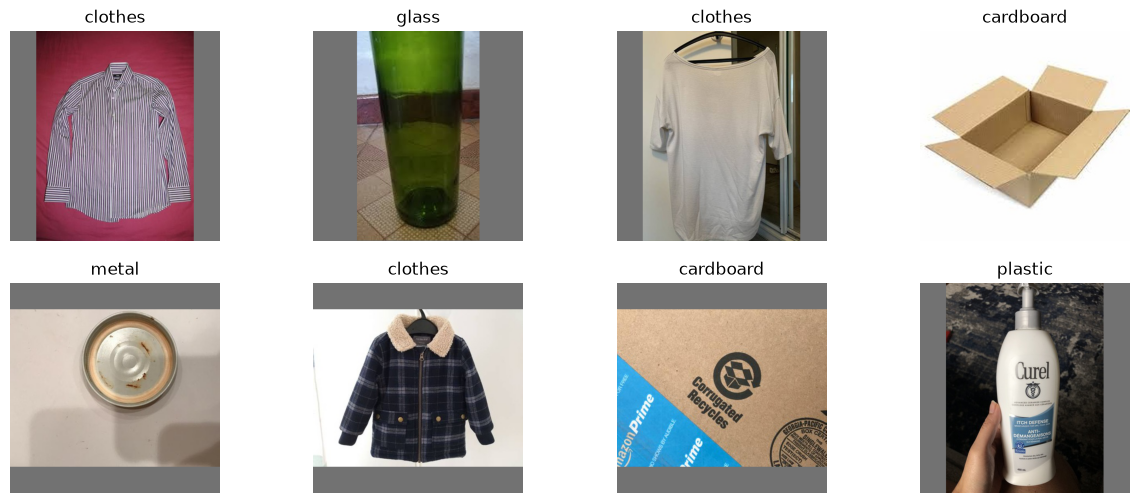

In [7]:
sample = dataset.shuffle(seed=42)[:8]
images = sample["image"]
true_labels = sample["label"]

plt.figure(figsize=(15, 6))
for i, image in enumerate(images):
        plt.subplot(2, int(len(images)/2), i + 1)
        plt.imshow(image)
        plt.title(labels[true_labels[i]]) # adding title to the images for more informative plot
        plt.axis('off') #elimitating axis in plot for a cleaner view 

## Dataframe Construction

In [9]:
from transformers import CLIPVisionModelWithProjection
from utils import embedding_dataframe_construction, get_device

device = get_device()

vision_model = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-base-patch32").to(device)

train_df = embedding_dataframe_construction(train, train['label'], vision_model)
test_df = embedding_dataframe_construction(test, test['label'], vision_model)

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 45545.71it/s]
[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch32
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.sel

## Building a Machine Learning Model using CLIP encoder

In [15]:
#data sample separtion for training and testing models
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_df.drop(columns = ['Class']), test_df.drop(columns = ['Class']), train_df['Class'], test_df['Class']

sc = StandardScaler()
X_train_std = sc.fit_transform(X_train)
X_test_std = sc.transform(X_test)

pca = PCA(n_components = 0.95, svd_solver='full')
Lr_Model = LogisticRegression(random_state=1, solver='lbfgs')

X_train_pca = pca.fit_transform(X_train_std)
X_test_pca = pca.transform(X_test_std)

Lr_Model.fit(X_train_pca, y_train)

print('Model fully fitted')
## LOG Features change in order to see dim reduction
## PLOT PCA Results 




Model fully fitted



Results:    
Accuracy:               0.9347
Precision (macro):      0.9239
Recall (macro):         0.9350
F1 (macro):             0.9284
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       151
           1       0.99      0.99      0.99       140
           2       0.93      0.93      0.93       282
           3       1.00      1.00      1.00       379
           4       0.91      0.91      0.91       347
           5       0.91      0.88      0.89       186
           6       0.93      0.90      0.91       267
           7       0.89      0.86      0.87       319
           8       1.00      0.99      0.99       290
           9       0.72      0.90      0.80        91

    accuracy                           0.93      2452
   macro avg       0.92      0.93      0.93      2452
weighted avg       0.94      0.93      0.94      2452



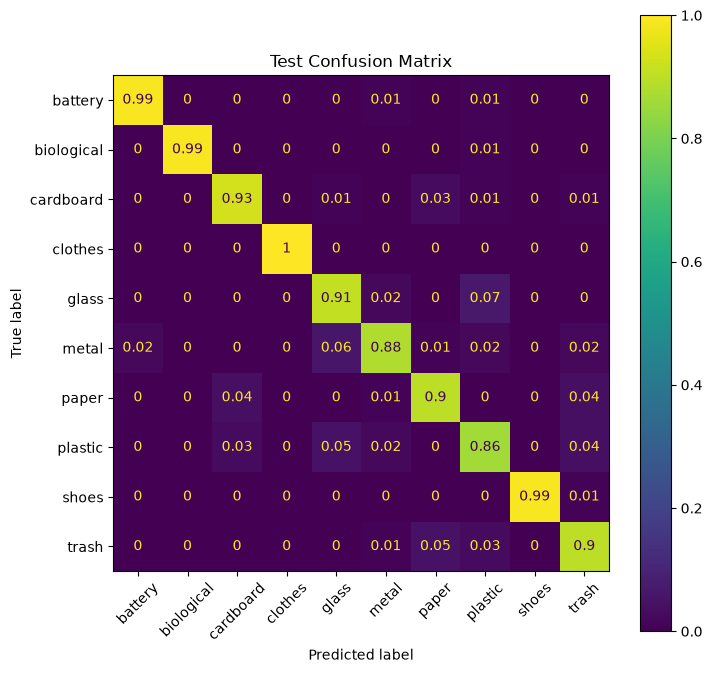

In [16]:
from utils import evaluate_predictions, plot_conf_matrix

predictions = Lr_Model.predict(X_test_pca)

metrics_dict = evaluate_predictions(y_test, predictions)
plot_conf_matrix(y_test, predictions, display_labels=labels, title="Test Confusion Matrix")

## PCA Visualization

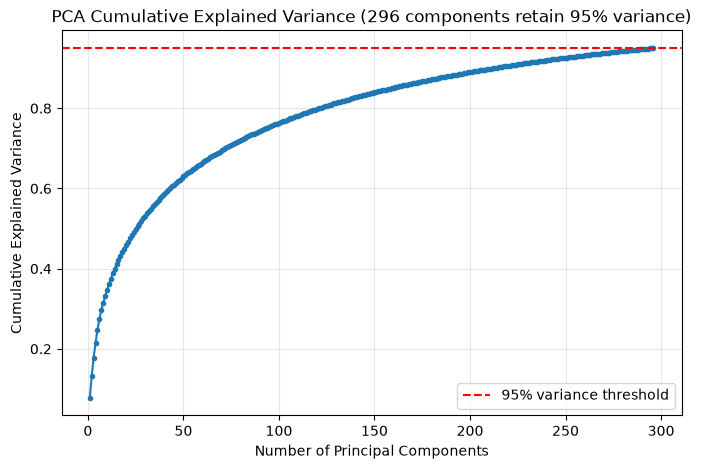

Original feature dimensionality: 512
Number of PCA components (95% variance): 296


In [17]:
explained_var = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_var)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', markersize=3)
plt.axhline(y=0.95, color='r', linestyle='--', label='95% variance threshold')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.title(f'PCA Cumulative Explained Variance ({pca.n_components_} components retain 95% variance)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Original feature dimensionality: {X_train_std.shape[1]}")
print(f"Number of PCA components (95% variance): {pca.n_components_}")

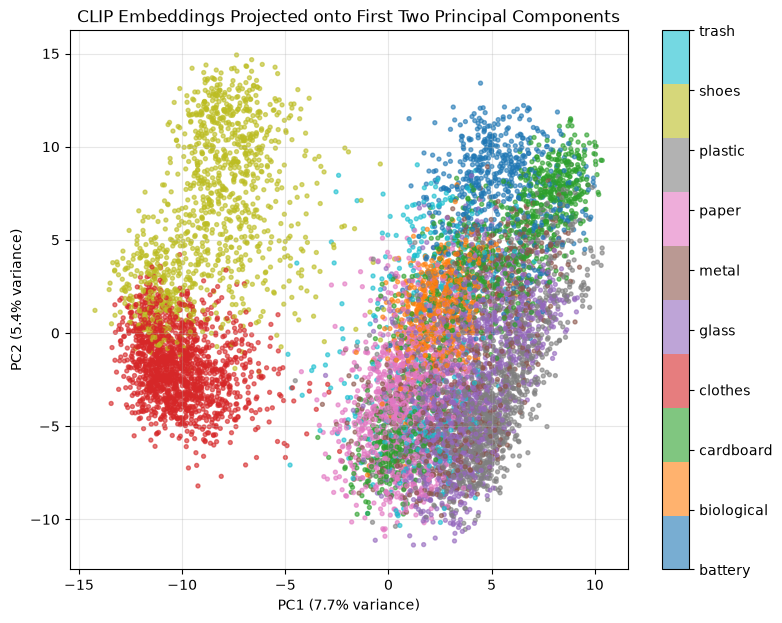

In [18]:
pca_2d = X_train_pca[:, :2]

plt.figure(figsize=(9, 7))
scatter = plt.scatter(pca_2d[:, 0], pca_2d[:, 1], c=y_train, cmap='tab10', s=8, alpha=0.6)
plt.xlabel(f'PC1 ({explained_var[0]*100:.1f}% variance)')
plt.ylabel(f'PC2 ({explained_var[1]*100:.1f}% variance)')
plt.title('CLIP Embeddings Projected onto First Two Principal Components')
cbar = plt.colorbar(scatter, ticks=range(len(labels)))
cbar.ax.set_yticklabels(labels)
plt.grid(alpha=0.3)
plt.show()

## Model Comparison Using PCA and Not PCA

In [19]:
%pip install xgboost lightgbm

import time
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

Note: you may need to restart the kernel to use updated packages.


In [ ]:
models = {
    "Logistic Regression": LogisticRegression(random_state=1, solver='lbfgs', max_iter=1000),
    "MLP": MLPClassifier(random_state=1, max_iter=300, hidden_layer_sizes=(128,)),
    "SVC": SVC(random_state=1, kernel='rbf'),
    "Random Forest": RandomForestClassifier(random_state=1, n_estimators=300, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=1, eval_metric='mlogloss', n_jobs=-1),
    "LightGBM": LGBMClassifier(random_state=1, n_jobs=-1, verbose=-1),
}

feature_sets = {
    "Without PCA": (X_train_std, X_test_std),
    "With PCA": (X_train_pca, X_test_pca),
}

results = []

for feature_label, (X_tr, X_te) in feature_sets.items():
    for model_name, model in models.items():
        start = time.time()
        model.fit(X_tr, y_train)
        train_time = time.time() - start

        preds = model.predict(X_te)

        results.append({
            "Model": model_name,
            "Features": feature_label,
            "Accuracy": accuracy_score(y_test, preds),
            "Precision (macro)": precision_score(y_test, preds, average='macro', zero_division=0),
            "Recall (macro)": recall_score(y_test, preds, average='macro', zero_division=0),
            "F1 (macro)": f1_score(y_test, preds, average='macro', zero_division=0),
            "Train Time (s)": train_time,
        })
        print(f"{model_name:22s} | {feature_label:12s} -> done in {train_time:6.1f}s")

results_df = pd.DataFrame(results)
results_df

Logistic Regression    | Without PCA  -> done in    0.4s
MLP                    | Without PCA  -> done in    2.8s
SVC                    | Without PCA  -> done in    5.5s


: 

In [ ]:
results_df.sort_values("Accuracy", ascending=False).reset_index(drop=True)

,Model,Features,Accuracy,Precision (macro),Recall (macro),F1 (macro),Train Time (s)
0,SVC,With PCA,0.964519,0.957448,0.959481,0.958384,9.292246
1,SVC,Without PCA,0.964111,0.956726,0.959151,0.957858,17.827294
2,MLP,With PCA,0.957178,0.949330,0.955851,0.952343,7.017285
3,MLP,Without PCA,0.955546,0.947029,0.951992,0.949188,5.170330
4,LightGBM,Without PCA,0.951876,0.947757,0.943423,0.945405,27.334596
5,LightGBM,With PCA,0.949429,0.948026,0.939841,0.943366,15.037161
6,XGBoost,Without PCA,0.948613,0.943002,0.942234,0.942359,39.739222
7,Random Forest,With PCA,0.946574,0.947429,0.934768,0.940317,14.228354
8,XGBoost,With PCA,0.945351,0.938036,0.936876,0.937302,21.938285
9,Logistic Regression,Without PCA,0.940865,0.929540,0.939018,0.933562,1.059426


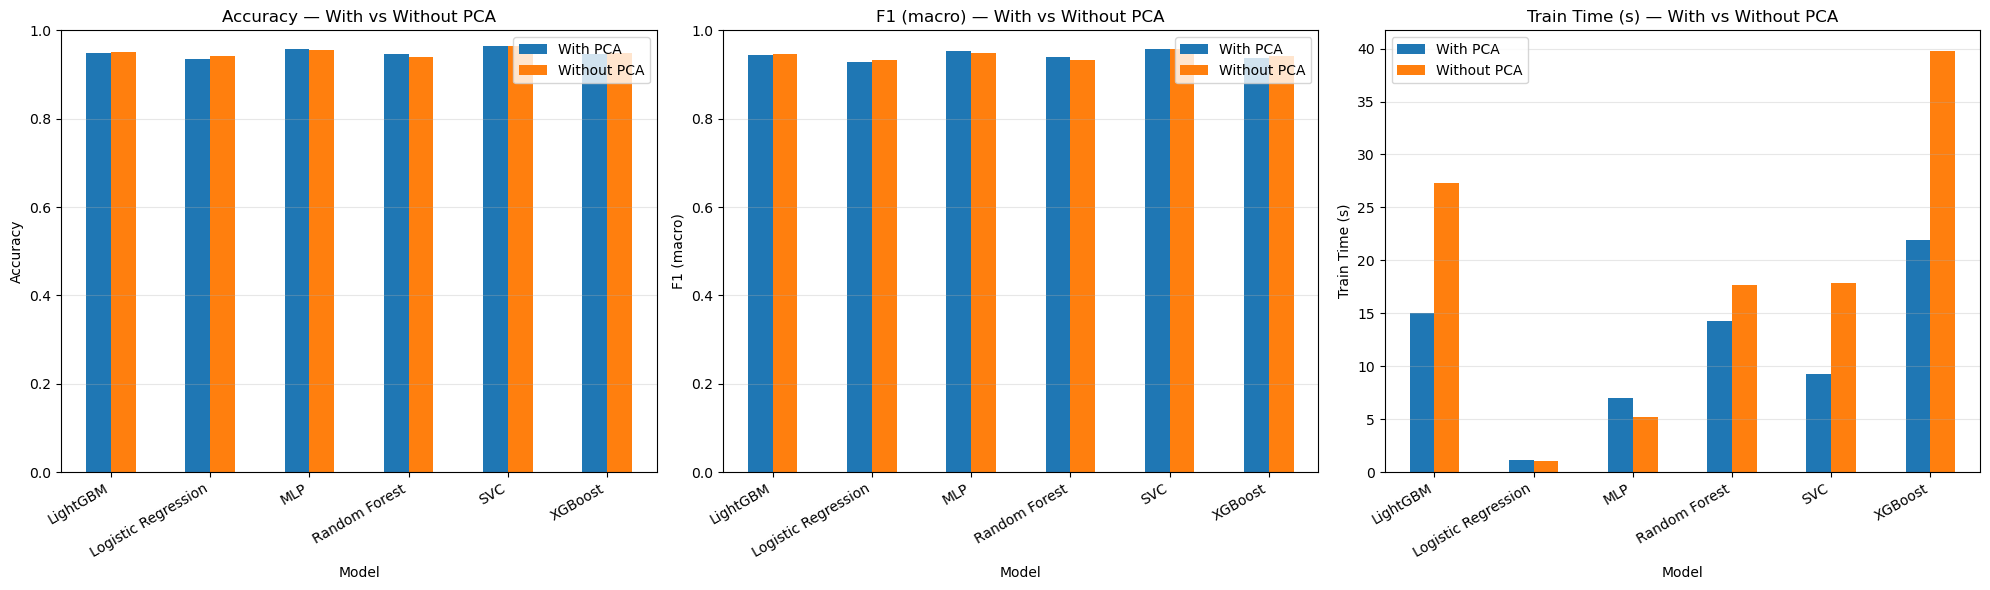

In [ ]:
metrics_to_plot = ["Accuracy", "F1 (macro)", "Train Time (s)"]

fig, axes = plt.subplots(1, len(metrics_to_plot), figsize=(20, 6))

for ax, metric in zip(axes, metrics_to_plot):
    pivot = results_df.pivot(index="Model", columns="Features", values=metric)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(f"{metric} \u2014 With vs Without PCA")
    ax.set_ylabel(metric)
    if metric != "Train Time (s)":
        ax.set_ylim(0, 1)
    ax.legend(title="")
    ax.grid(axis='y', alpha=0.3)
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

Best model: SVC (With PCA)
              precision    recall  f1-score   support

     battery       0.98      0.99      0.99       151
  biological       1.00      0.99      0.99       140
   cardboard       0.95      0.96      0.96       282
     clothes       1.00      1.00      1.00       379
       glass       0.96      0.96      0.96       347
       metal       0.93      0.96      0.94       186
       paper       0.97      0.94      0.96       267
     plastic       0.93      0.92      0.93       319
       shoes       1.00      0.99      1.00       290
       trash       0.85      0.87      0.86        91

    accuracy                           0.96      2452
   macro avg       0.96      0.96      0.96      2452
weighted avg       0.96      0.96      0.96      2452



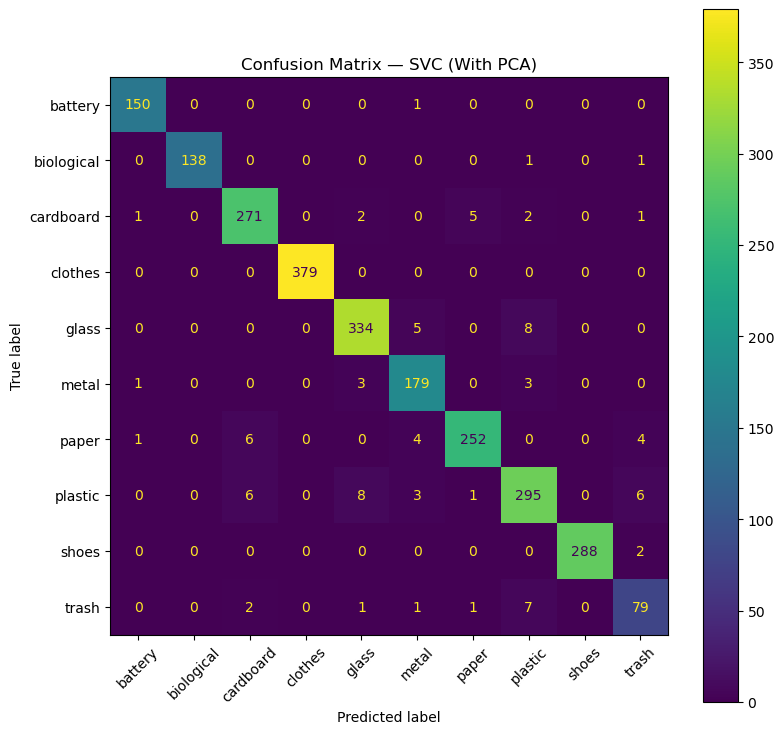

In [ ]:
# Confusion matrix for the best-performing model (with PCA)
best_row = results_df.sort_values("Accuracy", ascending=False).iloc[0]
best_model_name, best_feature_label = best_row["Model"], best_row["Features"]
best_model = models[best_model_name]

X_te_best = X_test_pca if best_feature_label == "With PCA" else X_test_std
preds_best = best_model.predict(X_te_best)

print(f"Best model: {best_model_name} ({best_feature_label})")

print(classification_report(y_test, preds_best, target_names=labels))
plot_conf_matrix(y_test, preds_best, display_names=labels, title=f"Confusion Matrix \u2014 {best_model_name} ({best_feature_label})")